# imports et chargement

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

trips = pd.read_parquet("../data/processed/trips.parquet")

# 50 000 trajets au hasard (le jeu complet est trop gros), type de vélo connu
df = trips.dropna(subset=["is_electric"]).sample(50000, random_state=42).copy()


# 2. Variables

In [5]:
df["log_duration"] = np.log(df["duration"])    # log car distributions très asymétriques
df["log_distance"] = np.log(df["distance"])

features = ["log_duration", "log_distance", "speed_kmh", "hour",
            "is_weekend", "is_electric", "free_floating_end"]
X = df[features].astype(float)
X.describe()


,log_duration,log_distance,speed_kmh,hour,is_weekend,is_electric,free_floating_end
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,6.706052,7.240534,7.311271,13.837280,0.229900,0.156700,0.103600
std,0.812823,0.712059,3.316745,5.125256,0.420773,0.363521,0.304744
min,4.795791,3.923222,0.250155,0.000000,0.000000,0.000000,0.000000
25%,6.173786,6.783380,5.136614,10.000000,0.000000,0.000000,0.000000
50%,6.579251,7.205421,7.524040,14.000000,0.000000,0.000000,0.000000
75%,7.090077,7.722290,9.628731,18.000000,0.000000,0.000000,0.000000
max,10.259762,9.903460,15.045201,23.000000,1.000000,1.000000,1.000000


# 3. Standardisation et ACP

In [6]:
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.8)          # garde les axes qui expliquent 80 % de la variance
Z = pca.fit_transform(X_scaled)
print("axes retenus :", pca.n_components_)
print("variance expliquée :", pca.explained_variance_ratio_.round(2))

# contribution des variables aux axes
pd.DataFrame(pca.components_.T, index=features,
             columns=[f"axe {i+1}" for i in range(pca.n_components_)]).round(2)


axes retenus : 5
variance expliquée : [0.23 0.2  0.15 0.14 0.13]


,axe 1,axe 2,axe 3,axe 4,axe 5
log_duration,0.66,-0.40,-0.04,-0.11,0.15
log_distance,0.69,0.30,-0.15,0.07,0.11
speed_kmh,0.02,0.80,-0.12,0.19,-0.03
hour,-0.01,-0.09,0.74,0.39,0.13
is_weekend,0.16,-0.15,-0.09,0.73,-0.57
is_electric,0.17,0.26,0.52,-0.01,0.27
free_floating_end,-0.18,-0.13,-0.36,0.51,0.75


# 4. Choix du nombre de groupes




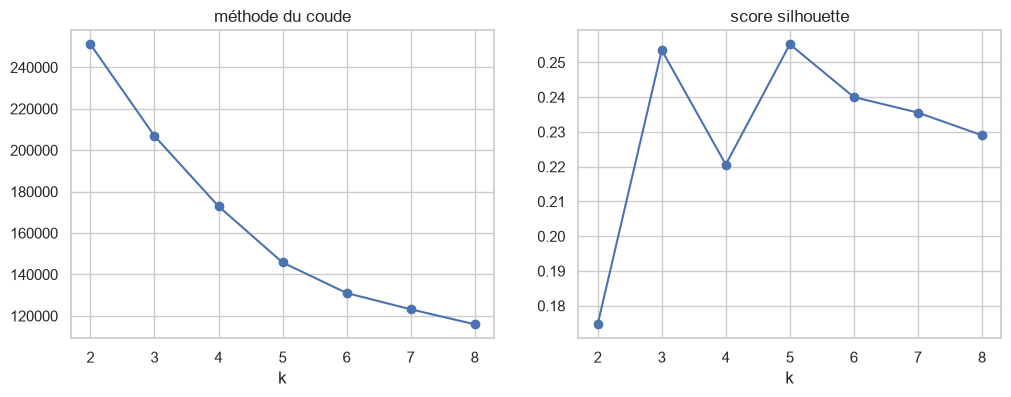

In [7]:
inertias, silhouettes = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z[:10000], km.labels_[:10000]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, "o-");    ax[0].set_title("méthode du coude"); ax[0].set_xlabel("k")
ax[1].plot(ks, silhouettes, "o-"); ax[1].set_title("score silhouette"); ax[1].set_xlabel("k")
plt.show()


# 5. K-means final

In [11]:
k = 5
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
df["cluster"] = kmeans.labels_
df["cluster"].value_counts().sort_index()


cluster
0     8455
1    17109
2    12491
3     5040
4     6905
Name: count, dtype: int64

# 6. Profil des groupes




In [12]:
profil = df.groupby("cluster").agg(
    nb_trajets   = ("cluster", "size"),
    duree_min    = ("duration", lambda x: x.median() / 60),
    distance_km  = ("distance", lambda x: x.median() / 1000),
    vitesse_kmh  = ("speed_kmh", "median"),
    heure_moy    = ("hour", "mean"),
    part_weekend = ("is_weekend", "mean"),
    part_elec    = ("is_electric", "mean"),
    part_hors_station = ("free_floating_end", "mean"),
)
profil.round(2)


,nb_trajets,duree_min,distance_km,vitesse_kmh,heure_moy,part_weekend,part_elec,part_hors_station
cluster,,,,,,,,
0,8455,12.0,1.43,7.48,14.24,1.00,0.09,0.00
1,17109,8.0,0.95,7.21,13.52,0.00,0.06,0.00
2,12491,15.0,2.39,10.13,13.97,0.04,0.38,0.00
3,5040,10.0,1.12,7.20,13.72,0.25,0.08,1.00
4,6905,48.0,1.68,2.16,13.97,0.17,0.13,0.02


# 7. Graphiques




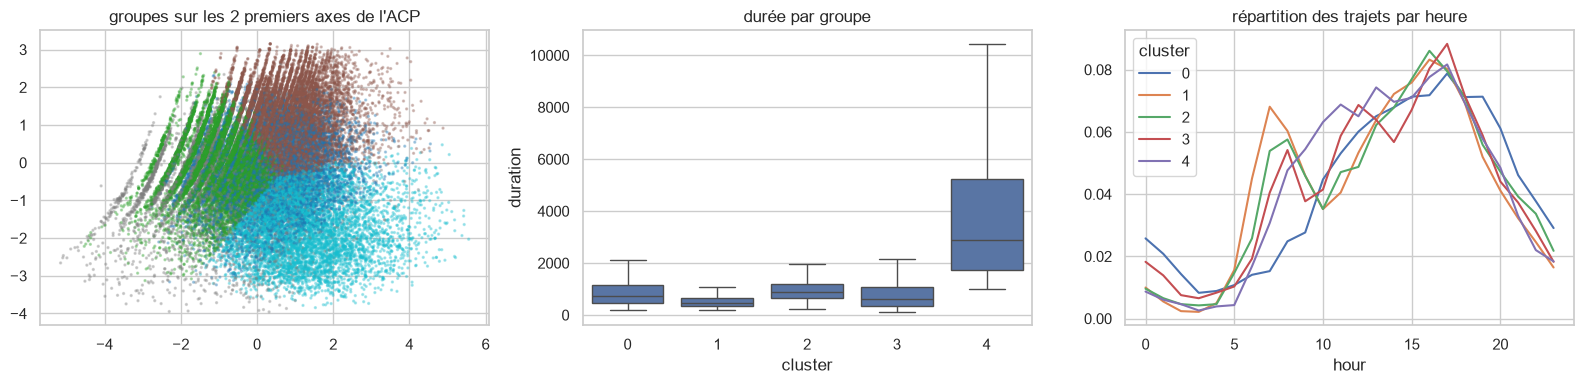

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(Z[:, 0], Z[:, 1], c=df["cluster"], cmap="tab10", s=2, alpha=.3)
ax[0].set_title("groupes sur les 2 premiers axes de l'ACP")

sns.boxplot(data=df, x="cluster", y="duration", showfliers=False, ax=ax[1])
ax[1].set_title("durée par groupe")

(df.groupby(["hour", "cluster"]).size().unstack()
   .pipe(lambda t: t / t.sum())
   .plot(ax=ax[2], title="répartition des trajets par heure"))
plt.tight_layout(); plt.show()
